# Explainable AI: Top Feature Attribution Coefficients

Extracts and visualizes the top linguistic predictors of Fake vs. Genuine reviews from the trained classifier.

**Generates:** `12_top_feature_coefficients.png`


### 1. Environment & Path Configuration

In [1]:
import os
import sys
import matplotlib.pyplot as plt
%matplotlib inline

# Navigate to project root if running from notebooks directory
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print('Active Project Root:', os.getcwd())


Active Project Root: e:\ML\mini project 2


### 2. Execution & Visualization Generation

Loading existing coefficients from results/metrics\top_feature_coefficients.csv...


C:\Users\Tauqeer Rizvi\AppData\Local\Temp\ipykernel_31752\1767854569.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Tauqeer Rizvi\AppData\Local\Temp\ipykernel_31752\1767854569.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


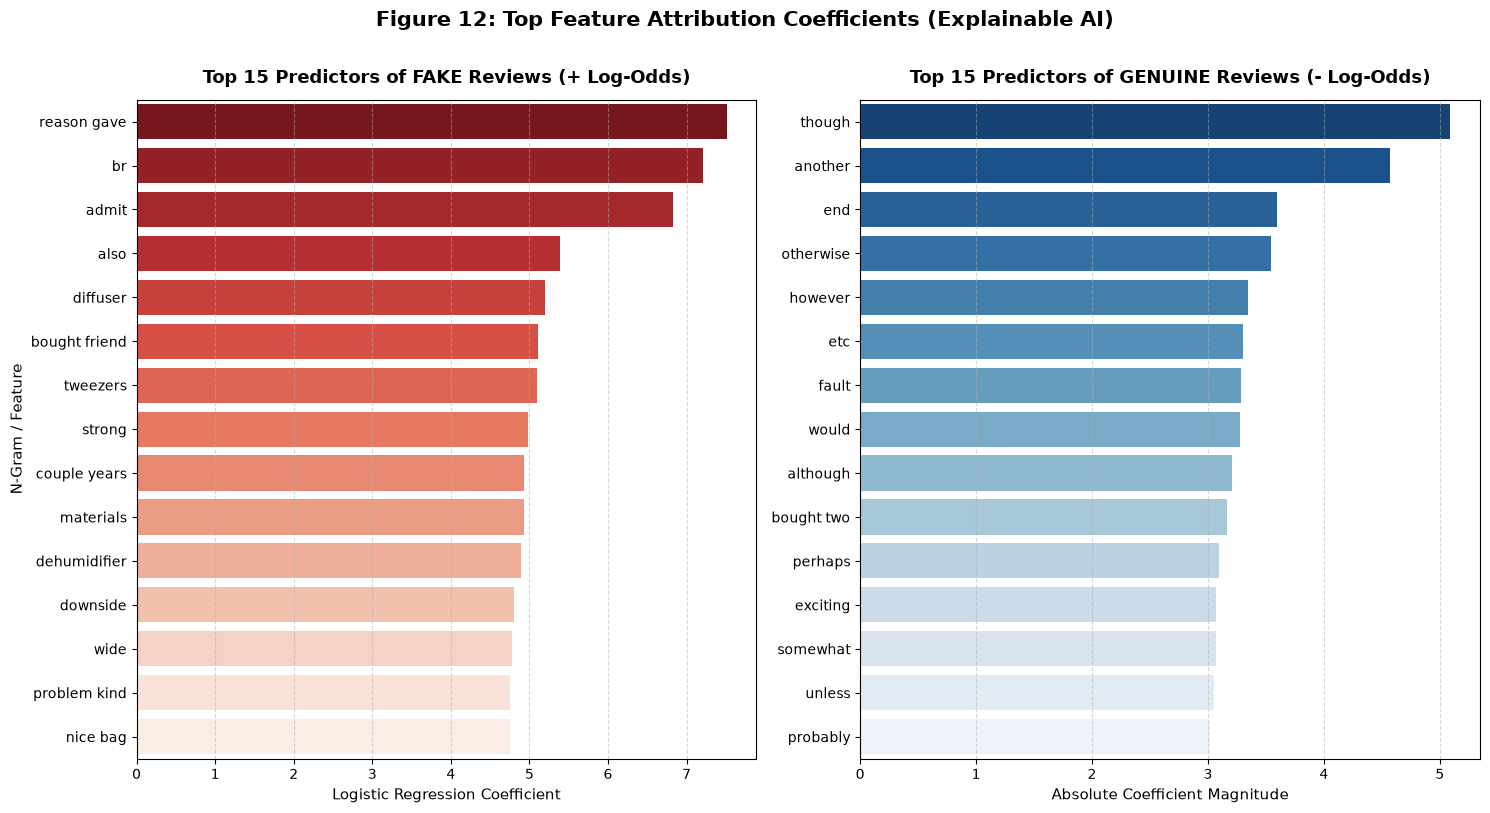

Successfully generated and saved: results/figures\12_top_feature_coefficients.png


In [2]:
import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

FIGURES_DIR = "results/figures"
METRICS_DIR = "results/metrics"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

# 1. Load or extract top feature coefficients
csv_path = os.path.join(METRICS_DIR, "top_feature_coefficients.csv")
if os.path.exists(csv_path):
    print(f"Loading existing coefficients from {csv_path}...")
    df_coef = pd.read_csv(csv_path)
else:
    print("Extracting coefficients from trained model...")
    model = joblib.load("models/best_model_enhanced.joblib")
    tfidf = model.named_steps["tfidf"]
    clf = model.named_steps["classifier"]
    feature_names = tfidf.get_feature_names_out()
    coefs = clf.coef_[0]
    df_coef = pd.DataFrame({
        "feature": feature_names,
        "coefficient": coefs,
        "odds_ratio": np.exp(coefs)
    }).sort_values(by="coefficient", ascending=False)
    df_coef.to_csv(csv_path, index=False)

top_fake = df_coef.head(15).copy()
top_honest = df_coef.tail(15).iloc[::-1].copy()

# 2. Generate Figure 12: Top Feature Coefficients
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=False)

# Left: Deceptive Predictors (+ coefficient)
sns.barplot(
    data=top_fake,
    x="coefficient",
    y="feature",
    palette="Reds_r",
    ax=axes[0]
)
axes[0].set_title("Top 15 Predictors of FAKE Reviews (+ Log-Odds)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Logistic Regression Coefficient", fontsize=11)
axes[0].set_ylabel("N-Gram / Feature", fontsize=11)
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

# Right: Genuine Predictors (- coefficient)
top_honest_plot = top_honest.copy()
top_honest_plot["abs_coefficient"] = top_honest_plot["coefficient"].abs()
sns.barplot(
    data=top_honest_plot,
    x="abs_coefficient",
    y="feature",
    palette="Blues_r",
    ax=axes[1]
)
axes[1].set_title("Top 15 Predictors of GENUINE Reviews (- Log-Odds)", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Absolute Coefficient Magnitude", fontsize=11)
axes[1].set_ylabel("")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.suptitle("Figure 12: Top Feature Attribution Coefficients (Explainable AI)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()

out_fig = os.path.join(FIGURES_DIR, "12_top_feature_coefficients.png")
out_met = os.path.join(METRICS_DIR, "12_top_feature_coefficients.png")
fig.savefig(out_fig, dpi=300, bbox_inches="tight")
fig.savefig(out_met, dpi=300, bbox_inches="tight")
plt.show()

print(f"Successfully generated and saved: {out_fig}")
